# MedRoute — demonstração narrada
**Tech Challenge · Fase 2 · Projeto 2 — Otimização de rotas para distribuição de medicamentos e insumos**

Este notebook percorre a solução de ponta a ponta:

1. o cenário do dia (entregas, prioridades, frota e restrições);
2. o ponto de partida — o algoritmo genético do **código base** de TSP — e por que ele não basta;
3. o **algoritmo genético do MedRoute** (representação, fitness, operadores) rodando no cenário;
4. as rotas otimizadas no **mapa**, na linha do tempo e na ocupação da frota;
5. o **comparativo** com outras abordagens de roteamento;
6. a **semana operacional** simulada;
7. a **integração com a LLM**: instruções, relatório, perguntas em linguagem natural e a avaliação
   automática (guardrails).

In [1]:
import sys, json
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import pandas as pd
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 60)

from medroute.scenario import default_scenario
from medroute.problem import Problem
from medroute.ga import GAConfig, GeneticAlgorithm
from medroute.plan import RoutePlan
from medroute.baselines import nearest_neighbor, run_baseline, split_tour_greedy
from medroute.legacy_tsp import run_base_tsp
from medroute.viz import plots, static_map
from medroute.viz.folium_map import build_route_map
print("MedRoute importado de", RAIZ / "src")

MedRoute importado de C:\Users\enior\Downloads\Tech_Challenge-main\fase2\src


## 1. O cenário do dia

Dados **sintéticos e reprodutíveis** (semente 42) sobre a geografia real de São Paulo: 36 entregas
saindo da Central de Abastecimento Farmacêutico do hospital universitário, para UBS, UPA, AME, CAPS,
Hospital Dia e pacientes em atendimento domiciliar (identificados só por código).

In [2]:
sc = default_scenario()
print(sc.description)
entregas = pd.DataFrame([{"id": d.id, "destino": d.name, "tipo": d.kind, "prioridade": d.priority.label,
                          "kg": d.demand_kg, "requisitos": ", ".join(sorted(d.requirements)) or "—",
                          "janela": f"{sc.clock(d.window[0])}–{sc.clock(d.window[1])}", "itens": d.items}
                         for d in sc.deliveries])
entregas.head(12)

36 entregas (8 críticas), 1156 kg, 5 veículos — dados sintéticos sobre a geografia de São Paulo.


,id,destino,tipo,prioridade,kg,requisitos,janela,itens
0,E01,UBS Água Branca,UBS,CRÍTICA,57.0,refrigerado,07:00–12:00,Vacinas e imunobiológicos (cadeia fria) · Kits de coleta...
1,E02,UBS Brooklin,UBS,CRÍTICA,63.5,refrigerado,07:00–12:00,"Vacinas e imunobiológicos (cadeia fria) · Luvas, seringa..."
2,E03,UBS Morumbi,UBS,ALTA,46.5,—,08:00–12:00,"Curativos especiais (hidrocoloide, alginato)"
3,E04,UBS Tatuapé,UBS,NORMAL,64.0,—,08:00–12:00,EPIs — máscaras e aventais · Kits de coleta laboratorial
4,E05,UBS Saúde,UBS,ALTA,56.0,—,08:00–12:00,"Curativos especiais (hidrocoloide, alginato)"
5,E06,UBS Mooca,UBS,NORMAL,75.0,—,07:00–15:00,"Kits de coleta laboratorial · Soro fisiológico 0,9% (cai..."
6,E07,UBS Higienópolis,UBS,ALTA,47.5,—,07:00–15:00,"Curativos especiais (hidrocoloide, alginato)"
7,E08,UBS Pompeia,UBS,NORMAL,36.0,—,07:00–15:00,Saneantes e material de limpeza hospitalar
8,E09,UPA Moema,UPA,ALTA,90.0,controlado,07:00–15:00,Morfina e fentanil (controlados — Portaria 344/98) · Sor...
9,E10,UPA Lapa,UPA,ALTA,63.5,controlado,07:00–15:00,Morfina e fentanil (controlados — Portaria 344/98)


In [3]:
print(entregas["prioridade"].value_counts().to_string())
pd.DataFrame([{"veículo": f"{v.id} · {v.name}", "capacidade (kg)": v.capacity_kg, "autonomia (km)": v.range_km,
               "km/h": v.speed_kmh, "R$/km": v.cost_per_km, "recursos": ", ".join(sorted(v.features)) or "—"}
              for v in sc.vehicles])

prioridade
ALTA       16
NORMAL     12
CRÍTICA     8


,veículo,capacidade (kg),autonomia (km),km/h,R$/km,recursos
0,V1 · Van Refrigerada 01,450,140,22,3.10,"controlado, refrigerado"
1,V2 · Van 02 (cofre),650,160,22,2.40,controlado
2,V3 · Van Elétrica 03,550,70,22,0.90,—
3,V4 · Moto 01 (baú térmico),25,60,28,0.45,refrigerado
4,V5 · Moto 02,25,60,28,0.45,—


**Restrições modeladas:** prioridade com prazo (crítica 2 h, alta 4 h), capacidade de carga, autonomia,
múltiplos veículos heterogêneos (VRP), cadeia fria (só V1 e V4), medicamentos controlados da Portaria
344/98 (só V1 e V2, que têm cofre), janelas de recebimento e jornada de 8 h.

## 2. Ponto de partida: o GA do código base

O código base resolve um **TSP**: um único "caixeiro" visita todos os pontos, sem carga, autonomia,
prioridade ou horário. Ele tinha também um bug: `order_crossover(parent1, parent1)` — o pai cruzava com
ele mesmo e não havia recombinação. Abaixo, o GA do base (reproduzido em `legacy_tsp.py`) com e sem a
correção, e o que acontece quando a rota única é fatiada entre os veículos.

In [4]:
problema = Problem(sc)
com_bug = run_base_tsp(problema.dist_np, generations=600, seed=1, fix_crossover_bug=False)
corrigido = run_base_tsp(problema.dist_np, generations=600, seed=1)
print(f"TSP do base como fornecido : {com_bug.best_distance:.1f} km")
print(f"TSP do base corrigido      : {corrigido.best_distance:.1f} km")

tour = [c for c in corrigido.best_tour if c != 0]
fatiado = problema.evaluate(split_tour_greedy(problema, tour))
plano_base = RoutePlan.from_evaluation(problema, fatiado, "TSP do código base + fatiamento")
print(plano_base.summary_text())

TSP do base como fornecido : 273.7 km
TSP do base corrigido      : 191.1 km
TSP do código base + fatiamento — Distribuição diária — 2026-10-13
  36 entregas | 3/5 veículos | 215.6 km | R$ 1,216.18 | 18.6 h de rota | CO2 41.9 kg
  No prazo: 69.4% {'CRÍTICA': 25.0, 'ALTA': 75.0, 'NORMAL': 91.7} | atrasos: 11 (críticos: 6) | violações: 8 | fitness 21706.3
  V1 Van Refrigerada 01: 9 paradas, 70.7/140 km, 190/450 kg, volta 12:58
      E36 → E30 → E16 → E33 → E17 → E23 → E34 → E25 → E05
  V2 Van 02 (cofre): 16 paradas, 80.7/160 km, 582/650 kg, volta 14:25  VIOLAÇÕES {'incompatibilidade': 3.0}
      E12 → E14 → E10 → E28 → E22 → E26 → E03 → E32 → E09 → E27 → E02 → E06 → E35 → E21 → E31 → E04
  V3 Van Elétrica 03: 11 paradas, 64.3/70 km, 383/550 kg, volta 12:16  VIOLAÇÕES {'incompatibilidade': 5.0}
      E11 → E13 → E18 → E20 → E29 → E15 → E07 → E19 → E01 → E24 → E08
  V4 Moto 01 (baú térmico): não sai
  V5 Moto 02: não sai


A rota única é curta, mas ao dividi-la entre os veículos aparecem **violações**: insulina e vacinas
em veículo sem refrigeração, controlados sem cofre, capacidade estourada — e as entregas críticas
chegam tarde. Daí a necessidade de modelar o problema como **VRP com restrições**.

## 3. O algoritmo genético do MedRoute

* **Cromossomo**: permutação das 36 entregas + 4 separadores (um a menos que o número de veículos);
  o segmento *k* é a rota do veículo *k*.
* **Fitness** (minimizar): km + peso_prioridade × hora de chegada + peso × minutos de atraso +
  penalidades de capacidade, autonomia, compatibilidade e jornada.
* **Operadores**: torneio; OX/PMX/ERX/**BCRC**; swap, inversão, inserção, scramble, **prioridade** e
  **reparo**; elitismo, anti-duplicata, imigrantes; 2-opt/relocate (memético).

In [5]:
from medroute.ga import operators as ops
import random
rng = random.Random(3)
p1 = [1, 2, 3, 4, 5, 6, 7, 8, 9]
p2 = [9, 3, 7, 8, 2, 6, 5, 1, 4]
print("OX  :", ops.order_crossover(p1, p2, rng))
print("PMX :", ops.pmx_crossover(p1, p2, rng))
print("ERX :", ops.edge_recombination(p1, p2, rng))
ch = [1, 2, 3, 4, 5, 6, 7, 8, 9]
print("inversão:", ops.inversion_mutation(ch, rng), "| inserção:", ops.insertion_mutation(ch, rng))

OX  : [9, 3, 2, 4, 5, 6, 7, 8, 1]
PMX : [4, 3, 7, 8, 2, 6, 5, 1, 9]
ERX : [1, 5, 4, 9, 3, 7, 8, 2, 6]
inversão: [1, 2, 3, 4, 5, 6, 7, 9, 8] | inserção: [1, 2, 7, 3, 4, 5, 6, 8, 9]


In [6]:
marcos = {0, 5, 10, 25, 50, 100, 200, 300}
def progresso(st, rotas):
    if st.generation in marcos:
        print(f"geração {st.generation:3d} | fitness {st.best:9.1f} | {st.best_distance_km:6.1f} km | "
              f"viável: {st.best_feasible}")

res = GeneticAlgorithm(problema, GAConfig(), callback=progresso).run()   # mesma config do pipeline
plano = RoutePlan.from_evaluation(problema, res.evaluation, "MedRoute (algoritmo genético)", res.runtime_s)
print(f"\n{res.stop_reason} — {res.generations_run} gerações, {res.evaluations} avaliações, {res.runtime_s:.1f} s\n")
print(plano.summary_text())

geração   0 | fitness    3718.5 |  292.0 km | viável: False
geração   5 | fitness    1373.4 |  264.0 km | viável: True


geração  10 | fitness     798.6 |  282.9 km | viável: True


geração  25 | fitness     536.5 |  283.0 km | viável: True


geração  50 | fitness     529.7 |  273.9 km | viável: True


geração 100 | fitness     502.3 |  253.5 km | viável: True


geração 200 | fitness     502.3 |  253.5 km | viável: True


geração 300 | fitness     502.3 |  253.5 km | viável: True



sem melhora por 250 gerações — 351 gerações, 36571 avaliações, 10.9 s

MedRoute (algoritmo genético) — Distribuição diária — 2026-10-13
  36 entregas | 5/5 veículos | 253.5 km | R$ 1,178.08 | 19.1 h de rota | CO2 40.1 kg
  No prazo: 97.2% {'CRÍTICA': 87.5, 'ALTA': 100.0, 'NORMAL': 100.0} | atrasos: 1 (críticos: 1) | violações: 0 | fitness 502.3
  V1 Van Refrigerada 01: 8 paradas, 59.9/140 km, 312/450 kg, volta 11:37
      E02 → E01 → E11 → E33 → E29 → E24 → E10 → E30
  V2 Van 02 (cofre): 13 paradas, 63.3/160 km, 464/650 kg, volta 12:43
      E09 → E34 → E05 → E15 → E23 → E20 → E18 → E21 → E35 → E04 → E13 → E06 → E17
  V3 Van Elétrica 03: 8 paradas, 40.5/70 km, 338/550 kg, volta 10:41
      E07 → E12 → E08 → E16 → E14 → E26 → E03 → E32
  V4 Moto 01 (baú térmico): 4 paradas, 58.7/60 km, 24/25 kg, volta 10:06
      E28 → E31 → E25 → E27
  V5 Moto 02: 3 paradas, 31.1/60 km, 18/25 kg, volta 08:59
      E22 → E36 → E19


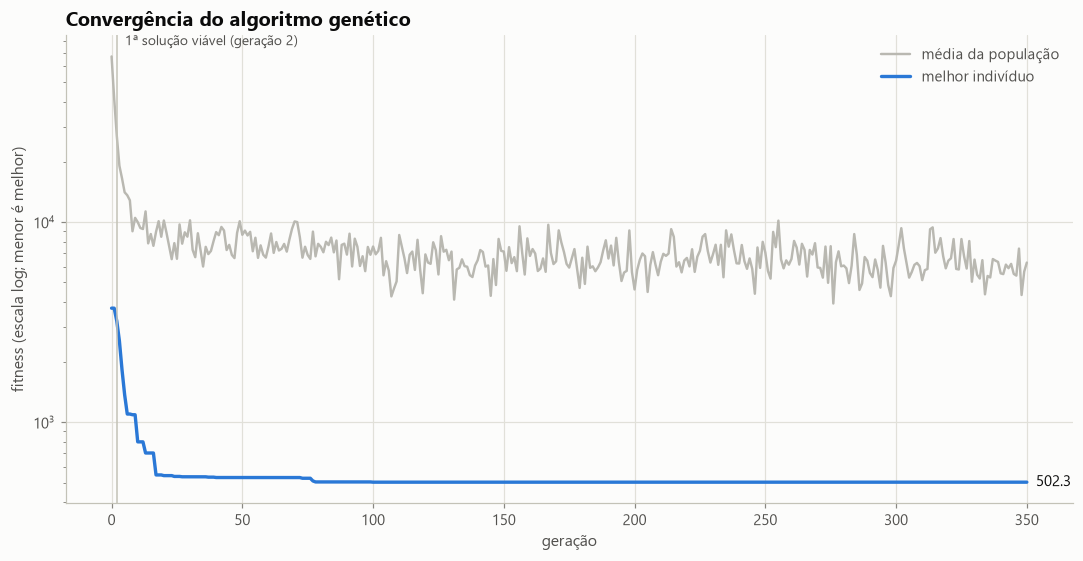

In [7]:
fig = plots.plot_convergence(res.history_dicts)

## 4. As rotas no mapa

Mapa interativo (camada por veículo, número = ordem de visita, forma = prioridade; clique numa parada
para ver itens, janela, prazo e chegada prevista).

In [8]:
build_route_map(plano)

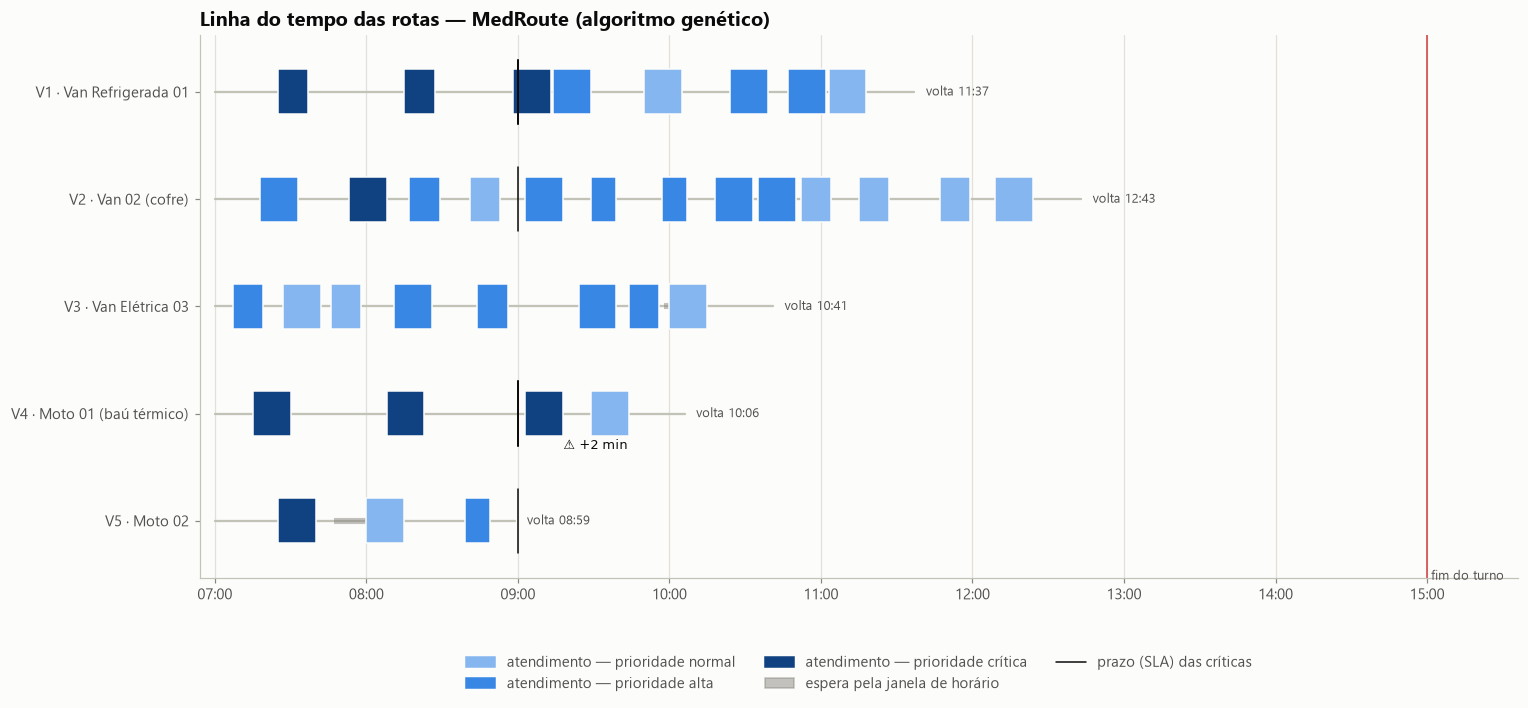

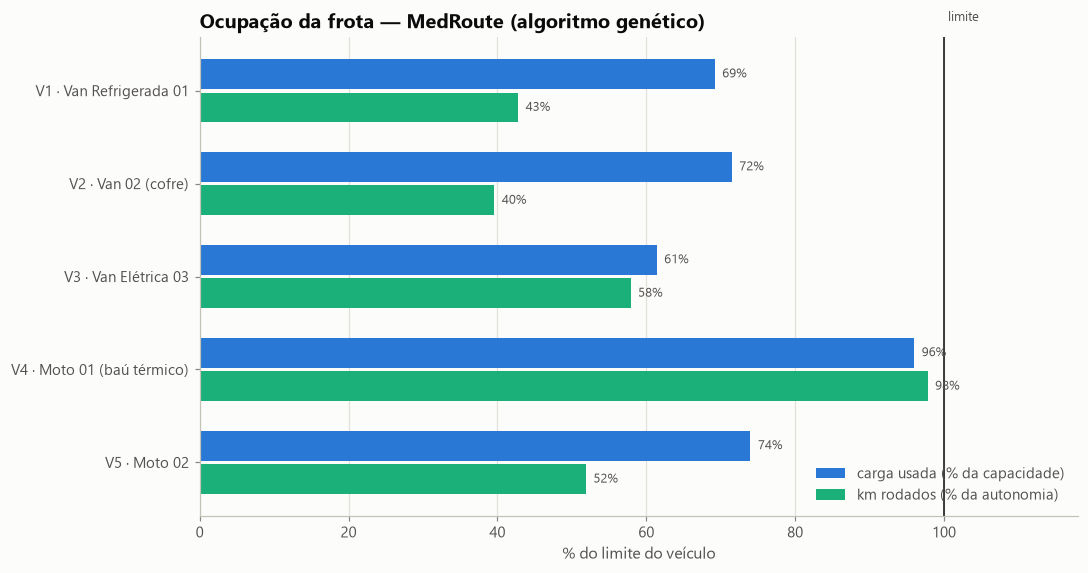

In [9]:
fig = plots.plot_gantt(plano)
fig = plots.plot_utilization(plano)

## 5. Comparativo com outras abordagens

Mesmo cenário e mesma função de avaliação. O "processo atual" é o despachante: atende primeiro as
urgências e, entre elas, a mais próxima.

In [10]:
linhas = []
for nome in ["tsp_base_split", "vizinho_mais_proximo", "despachante_prioridade", "clarke_wright",
             "sweep", "melhoria_local", "simulated_annealing"]:
    r = run_baseline(nome, problema)
    k = RoutePlan.from_evaluation(problema, r.evaluation, r.name, r.runtime_s).kpis
    linhas.append({"metodo": r.name, "km": k.total_km, "no_prazo_pct": k.on_time_pct,
                   "violacoes": k.violations, "fitness": k.fitness, "tempo_s": round(r.runtime_s, 2)})
k = plano.kpis
linhas.append({"metodo": "MedRoute (algoritmo genético)", "km": k.total_km, "no_prazo_pct": k.on_time_pct,
               "violacoes": k.violations, "fitness": k.fitness, "tempo_s": round(res.runtime_s, 2)})
comparativo = pd.DataFrame(linhas).sort_values("fitness")
comparativo

,metodo,km,no_prazo_pct,violacoes,fitness,tempo_s
7,MedRoute (algoritmo genético),253.5,97.2,0,502.27,10.85
6,Simulated Annealing,264.4,94.4,0,517.42,3.01
5,Despachante + busca local,276.1,97.2,0,888.08,0.12
4,Sweep + 2-opt,238.7,80.6,2,6638.62,0.25
2,Despachante (prioridade + vizinho),299.5,58.3,0,10475.22,0.00
1,Vizinho mais próximo,195.5,52.8,0,10735.78,0.00
3,Clarke & Wright (economias),210.2,66.7,2,13561.32,0.01
0,TSP do código base + fatiamento,202.3,63.9,5,17048.35,2.21


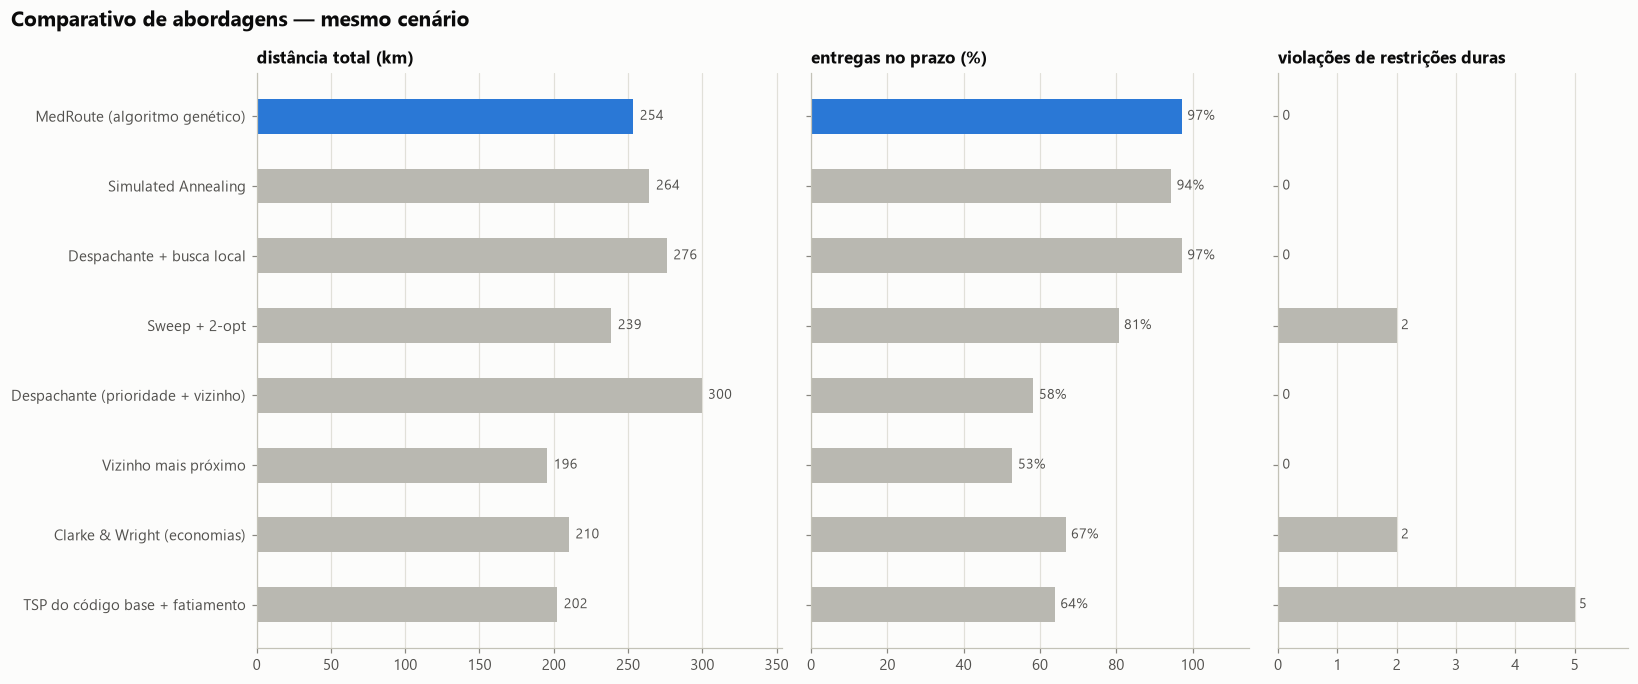

In [11]:
fig = plots.plot_methods_comparison(comparativo, "MedRoute (algoritmo genético)")

In [12]:
atual = RoutePlan.from_evaluation(problema, problema.evaluate(nearest_neighbor(problema, True)),
                                  "Processo atual (despachante)")
pd.Series(plano.compare(atual), name="MedRoute vs processo atual")

km_economizados            46.00
km_economizados_pct        15.40
reais_economizados        399.39
reais_economizados_pct     25.30
horas_economizadas          4.35
co2_evitado_kg             18.30
pontos_sla                 38.90
atrasos_evitados           14.00
violacoes_evitadas          0.00
Name: MedRoute vs processo atual, dtype: float64

O experimento completo — 10 sementes por método, ablação dos operadores, escalabilidade até 90 entregas e
OR-Tools — está em `scripts/run_experiments.py` e no relatório técnico.

## 6. Semana operacional simulada

,dia,entregas,km_atual,km_ga,km_economia_pct,sla_atual,sla_ga
0,Segunda,38,277.5,206.6,25.5,60.5,97.4
1,Terça,34,284.7,202.1,29.0,52.9,97.1
2,Quarta,33,245.9,182.5,25.8,48.5,100.0
3,Quinta,35,315.9,244.5,22.6,60.0,100.0
4,Sexta,30,209.4,179.0,14.5,66.7,100.0


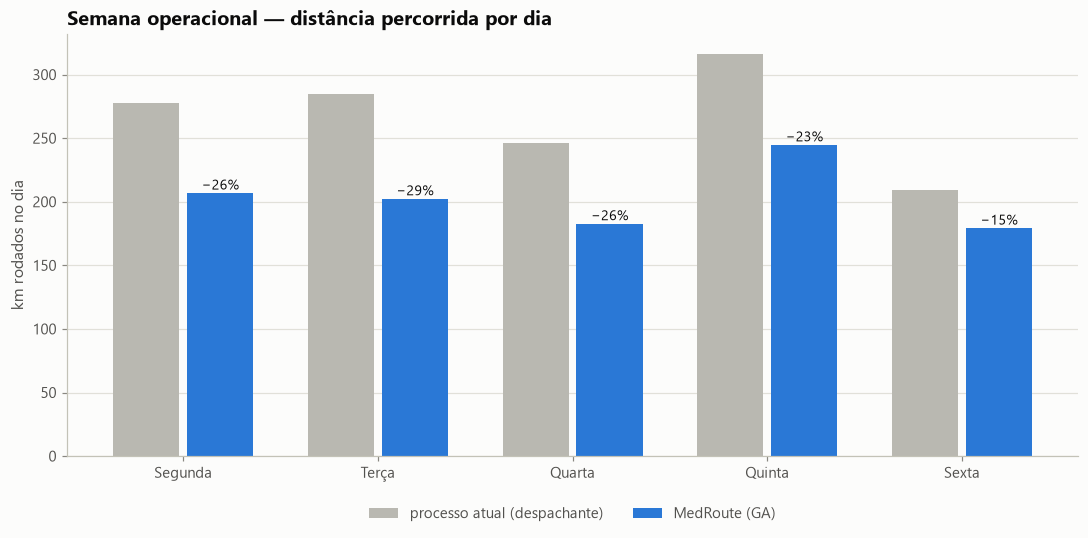

In [13]:
semana = pd.read_csv(RAIZ / "reports" / "operacao_semanal.csv")
fig = plots.plot_weekly(semana)
semana[["dia", "entregas", "km_atual", "km_ga", "km_economia_pct", "sla_atual", "sla_ga"]]

## 7. Integração com a LLM

`RouteAssistant` recebe o plano e gera os produtos pedidos no enunciado. Modo `auto`: usa a OpenRouter
(Nemotron 3 Ultra, gratuito) e cai para templates offline se faltar chave, rede ou cota. As respostas do
pipeline estão em cache — aqui elas voltam instantaneamente.

In [14]:
from medroute.llm import RouteAssistant
from IPython.display import Markdown, display
assistente = RouteAssistant(plano, atual, mode="auto")

r = assistente.driver_instructions("V4")
print(f"origem: {r.source} | modelo: {r.model} | fidelidade: {r.validation['nota']}/100")
display(Markdown(r.text))

origem: cache | modelo: nvidia/nemotron-3-ultra-550b-a55b:free | fidelidade: 100.0/100


## Rota V4 — Moto 01 (baú térmico)
**Resumo:** saída às 07:00 da Central, 4 entregas, 58.66 km, retorno previsto às 10:06, carga total 24.0 kg.

### Antes de sair
- Conferir a carga na ordem de entrega: E28 (3.5 kg), E31 (8.5 kg), E25 (5.5 kg), E27 (6.5 kg).
- Verificar integridade do baú térmico e registrar temperatura inicial (2–8 °C) para as 3 entregas refrigeradas.
- Confirmar autonomia da moto (60 km) frente aos 58.66 km planejados (uso de 97.8%).
- Checar ocupação de carga: 24.0 kg de 25 kg (96% da capacidade).
- Garantir documento de entrega e caneta para assinatura dos recebedores.

### Paradas (na ordem)
**1. 07:15 — Paciente PD-08 (Lapa)** (Lapa) · prioridade CRÍTICA · 3.5 kg
  - Itens: Insulina NPH e regular (cadeia fria)
  - Janela 07:00–12:00 · prazo 09:00 · manter refrigeração 2–8 °C até a entrega; prioridade CRÍTICA

**2. 08:08 — Paciente PD-11 (Tatuapé)** (Tatuapé) · prioridade CRÍTICA · 8.5 kg
  - Itens: Insulina NPH e regular (cadeia fria)
  - Janela 07:00–13:00 · prazo 09:00 · manter refrigeração 2–8 °C até a entrega; prioridade CRÍTICA

**3. 09:03 — Paciente PD-05 (Jabaquara)** (Jabaquara) · prioridade CRÍTICA · 5.5 kg
  - Itens: Insulina NPH e regular (cadeia fria)
  - Janela 07:00–12:00 · prazo 09:00 · manter refrigeração 2–8 °C até a entrega; prioridade CRÍTICA · **atraso previsto de 2 min**

**4. 09:29 — Paciente PD-07 (Campo Belo)** (Campo Belo) · prioridade NORMAL · 6.5 kg
  - Itens: Fraldas geriátricas e material de higiene
  - Janela 07:00–12:00 · prazo 12:00 · entrega sem exigência de temperatura

### Atenção
- Três entregas CRÍTICAS (E28, E31, E25) com prazo às 09:00; a terceira tem atraso previsto de 2 minutos.
- Autonomia no limite: 97.8% (58.66 km de 60 km); evite desvios.
- Carga no limite: 96% da capacidade (24.0 kg de 25 kg); não aceite volumes extras.
- Todas as insulinas exigem cadeia fria contínua (2–8 °C) do baú até a mão do paciente.

### Em caso de imprevisto
- Avisar a Central imediatamente (telefone da Central de Abastecimento Farmacêutico) se houver atraso, falha no baú ou trânsito severo.
- Priorizar as 3 entregas CRÍTICAS de insulina; a entrega NORMAL (E27) pode ser reagendada até 12:00.
- Nunca deixar insulinas fora do baú térmico; se o equipamento falhar, acionar veículo de apoio com refrigeração antes de prosseguir.

In [15]:
r = assistente.daily_report()
print(f"origem: {r.source} | fidelidade: {r.validation['nota']}/100")
display(Markdown(r.text))

origem: cache | fidelidade: 100.0/100


# Relatório diário de rotas — 2026-10-13

## Resumo executivo
O plano do MedRoute reduziu em 15,4% a quilometragem total e em 25,3% o custo operacional frente ao processo atual, garantindo 97,2% das entregas no prazo contra 58,3%. O único ponto crítico de atenção é o atraso de 2,5 minutos na entrega E25 (Paciente PD-05, Jabaquara), única entrega CRÍTICA fora do SLA.

## Indicadores
| Indicador | MedRoute | Processo atual | Diferença |
|---|---|---|---|
| km total | 253,5 | 299,5 | -46,0 (-15,4%) |
| custo total R$ | 1.178,08 | 1.577,47 | -399,39 (-25,3%) |
| horas de rota | 19,09 | 23,44 | -4,35 |
| CO2 kg | 40,1 | 58,4 | -18,3 |
| entregas no prazo % | 97,2% | 58,3% | +38,9 p.p. |
| críticas no prazo % | 87,5% | 37,5% | +50,0 p.p. |
| violações de restrição | 0 | 0 | 0 |

## Pontos de atenção
- **1 entrega CRÍTICA atrasada (E25):** 2,5 min além do prazo das 09:00, único atraso do dia.
- **Moto V4 com autonomia no limite:** 97,8% da autonomia utilizada (58,66 km de 60 km), margem de segurança reduzida.
- **Cadeia fria concentrada em dois veículos:** V1 (3 paradas refrigeradas) e V4 (3 paradas refrigeradas) exigem monitoramento contínuo de temperatura 2–8 °C.
- **Medicamentos controlados em V1 e V2:** 2 paradas controladas na V1 e 4 na V2 (Portaria 344/98), conferência documental obrigatória.

## Uso da frota
- **V1 (Van Refrigerada 01):** 59,87 km | 69,2% carga | 42,8% autonomia | retorno 11:37
- **V2 (Van 02 cofre):** 63,30 km | 71,5% carga | 39,6% autonomia | retorno 12:43
- **V3 (Van Elétrica 03):** 40,53 km | 61,4% carga | 57,9% autonomia | retorno 10:41
- **V4 (Moto 01 baú térmico):** 58,66 km | 96,0% carga | 97,8% autonomia | retorno 10:06
- **V5 (Moto 02):** 31,15 km | 74,0% carga | 51,9% autonomia | retorno 08:59

In [16]:
historico = []
for pergunta in ["Qual veículo leva a insulina do paciente PD-05 e a que horas chega?",
                 "Alguma entrega crítica corre risco de atraso? O que fazer?",
                 "Quais entregas de medicamentos controlados existem hoje e em quais veículos?",
                 "Qual é o telefone do paciente PD-08?"]:
    r = assistente.ask(pergunta, historico)
    historico.append((pergunta, r.text))
    display(Markdown(f"**P:** {pergunta}\n\n**R** _({r.source}, fidelidade {r.validation['nota']:.0f})_: {r.text}"))

**P:** Qual veículo leva a insulina do paciente PD-05 e a que horas chega?

**R** _(cache, fidelidade 100)_: A insulina do paciente PD-05 (entrega **E25**) é transportada pela **Moto 01 (baú térmico) — V4**, na **3ª parada** da rota.  
A chegada prevista é **09:03**, com **atraso previsto de 2 minutos** em relação ao prazo das 09:00.  
A entrega é **CRÍTICA** e exige **cadeia fria (refrigerado)**.

**P:** Alguma entrega crítica corre risco de atraso? O que fazer?

**R** _(cache, fidelidade 100)_: Sim. A entrega **E25** (Paciente PD-05, Jabaquara) — **CRÍTICA**, **refrigerada** (insulina) — na **Moto 01 (V4), 3ª parada**, tem **chegada prevista 09:03** com **atraso de 2 min** (prazo 09:00).  
No consolidado do turno há **1 entrega atrasada** e **1 crítica atrasada** (maior atraso 2,5 min; horário médio de entrega crítica 08:02).  
**Ação imediata:** monitorar V4 em tempo real; se o atraso aumentar, acionar moto reserva ou redistribuir a carga para veículo refrigerado mais próximo (V1 tem capacidade e recursos).  
Confirmar recebimento da insulina assim que entregue e registrar o desvio no painel MedRoute.

**P:** Quais entregas de medicamentos controlados existem hoje e em quais veículos?

**R** _(cache, fidelidade 100)_: Há **6 entregas com requisito "controlado"** (Portaria 344/98), distribuídas em **2 veículos**:

**V1 — Van Refrigerada 01**  
- 6ª parada: **E24** – Paciente PD-04 (Perdizes) – Morfina e fentanil – chegada **10:24**  
- 7ª parada: **E10** – UPA Lapa – Morfina e fentanil – chegada **10:47**

**V2 — Van 02 (cofre)**  
- 1ª parada: **E09** – UPA Moema – Morfina e fentanil + soro – chegada **07:18**  
- 5ª parada: **E23** – Paciente PD-03 (Ipiranga) – Morfina e fentanil – chegada **09:03**  
- 6ª parada: **E20** – CAPS Vila Prudente – Clonazepam e haloperidol – chegada **09:29**  
- 7ª parada: **E18** – CAPS Carrão – Clonazepam e haloperidol + EPIs – chegada **09:57**

Todos os veículos possuem o recurso **"controlado"** (V1 e V2).

**P:** Qual é o telefone do paciente PD-08?

**R** _(cache, fidelidade 100)_: Essa informação não está disponível no plano do dia.

### Avaliação automática (guardrails)

Cada resposta é conferida contra os dados. Abaixo, um texto propositalmente errado: um horário que não
existe, um ID inexistente e um antibiótico tratado como medicamento controlado (o erro real que a
avaliação encontrou na versão 1 do prompt).

In [17]:
from medroute.llm import guardrails
rota = plano.route("V5")
parada = rota.stops[0]
texto_errado = (f"### Paradas\n**1. {parada.arrival} — {parada.name}**\n"
                f"  - Entrega controlada (Portaria 344/98): colher lacre e assinatura.\n"
                f"### Atenção\n- Passar também na E99 às 03:33.\n")
guardrails.validate_route_text(texto_errado, rota, plano).to_dict()

{'nota': 35.3,
 'cobertura_paradas': 0.333,
 'ordem_correta': True,
 'horarios_citados': 0.333,
 'ids_inexistentes': ['E99'],
 'horarios_inventados': ['03:33'],
 'numeros_nao_rastreaveis': [],
 'requisitos_inventados': ['E22 tratado como controlado'],
 'observacoes': ['paradas não citadas: E36, E19']}

## Conclusão

* O GA do MedRoute encontra rotas **viáveis** (nenhuma restrição dura violada) que cumprem quase todos os
  prazos, com menos km e menos custo que o processo atual.
* As restrições hospitalares (prioridade, capacidade, autonomia, frota heterogênea, cadeia fria,
  controlados, janelas e jornada) entram na fitness por penalidade e são corrigidas por operadores
  especializados (BCRC, prioridade, reparo).
* A LLM transforma o plano em instruções, relatórios, sugestões e respostas — sempre com os números
  calculados pelo otimizador e com uma nota objetiva de fidelidade aos dados.